In [4]:
import pandas as pd
import glob
import os

files = glob.glob("/content/*.csv")

print("Uploaded CSV files:")
for f in files:
    print(os.path.basename(f))

# Select the actual rainfall file
rainfall_files = [
    f for f in files
    if "rainfall" in os.path.basename(f).lower()
    or "districtwise" in os.path.basename(f).lower()
]

if rainfall_files:
    df = pd.read_csv(rainfall_files[0])
    print("\nDataset loaded successfully!")
    print(df.head())
    print("\nColumns:", df.columns.tolist())
else:
    print("\nRainfall CSV not found. Upload it using the Files panel.")

Uploaded CSV files:
rainfall.csv

Dataset loaded successfully!
               State District        Date  Daily Actual  Daily Normal  \
0  ANDAMAN & NICOBAR  NICOBAR  2026-08-19           0.5           7.4   
1  ANDAMAN & NICOBAR  NICOBAR  2026-08-20           0.5           9.4   
2  ANDAMAN & NICOBAR  NICOBAR  2026-08-21           2.4           9.9   
3  ANDAMAN & NICOBAR  NICOBAR  2026-08-22           9.3           7.1   
4  ANDAMAN & NICOBAR  NICOBAR  2026-08-23           1.3           7.9   

  Daily Departure Per Daily Category                 Week Date  \
0                -94%             LD  13-08-2026 To 19-08-2026   
1                -94%             LD  13-08-2026 To 19-08-2026   
2                -76%             LD  13-08-2026 To 19-08-2026   
3                 31%              E  13-08-2026 To 19-08-2026   
4                -83%             LD  13-08-2026 To 19-08-2026   

   Weekly \nActual  Weekly Normal  ... Cumulative Date Cumulative Actual  \
0              0.5       

In [8]:
import pandas as pd

df = pd.read_csv("/content/rainfall.csv")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Daily Actual"] = pd.to_numeric(
    df["Daily Actual"], errors="coerce"
)

print("Date range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nAvailable districts:")
print(sorted(df["District"].dropna().unique()))

print("\nAvailable states:")
print(sorted(df["State"].dropna().unique()))

Date range:
2026-08-19 00:00:00 to 2026-10-21 00:00:00

Available districts:
['AGAR-MALWA', 'AHMADABAD', 'AHMADNAGAR', 'AIZAWL', 'AJMER', 'AKOLA', 'ALAPPUZHA', 'ALIRAJPUR', 'ALWAR', 'AMARAVATI', 'AMBALA', 'AMRELI', 'AMRITSAR', 'ANAKAPALLI', 'ANAND', 'ANANTAPURAMU', 'ANANTNAG', 'ANJAW', 'ANNAMAYYA DISTRICT', 'ANUGUL', 'ANUPPUR', 'ARARIYA', 'ARAVALLI', 'ARWAL', 'ASHOKNAGAR', 'AURANGABAD', 'BADGAM', 'BAGALKOT', 'BAJALI', 'BAKSA', 'BALAGHAT', 'BALANGIR', 'BALESHWAR', 'BALOD', 'BALODA BAZAR', 'BALRAMPUR', 'BANASKANTHA', 'BANDIPORE', 'BANGALORE RURAL', 'BANGLORE URBAN', 'BANKA', 'BANSWARA', 'BAPATLA', 'BARAGARH', 'BARAMULA', 'BARAN', 'BARMER', 'BARNALA', 'BARPETA', 'BARWANI', 'BASTAR', 'BATHINDA', 'BAUDA', 'BEGUSARAI', 'BELGAUM', 'BELLARY', 'BEMETARA', 'BETUL', 'BHABUA', 'BHADRAK', 'BHAGALPUR', 'BHANDARA', 'BHARATPUR', 'BHARUCH', 'BHAVNAGAR', 'BHILWARA', 'BHIND', 'BHIWANI', 'BHOJPUR', 'BHOPAL', 'BID', 'BIDAR', 'BIJAAPUR', 'BIJAPUR', 'BIKANER', 'BILAASPUR', 'BILASPUR', 'BISHNUPUR', 'BISWANATH

In [10]:
import numpy as np
import pandas as pd

# Read binary grid file (.grd) for 2022 rainfall
grd_path = '/content/Rainfall_ind2022_rfp25.grd'

try:
    # IMD daily gridded rainfall files are typically 365 or 366 days for a year
    # A 0.25 x 0.25 grid covers India latitude (6.5 to 38.5) and longitude (66.5 to 100.0)
    # This corresponds to a grid of size 129x135
    grid_cols = 135
    grid_rows = 129
    total_days = 365 # 2022 is a non-leap year

    # Read binary data
    data_binary = np.fromfile(grd_path, dtype=np.float32)
    print("Total binary data points:", len(data_binary))

    # Reshape and handle structure if it matches standard IMD format
    expected_size = total_days * grid_rows * grid_cols
    if len(data_binary) >= expected_size:
        data_reshaped = data_binary[:expected_size].reshape((total_days, grid_rows, grid_cols))
        # Replace standard IMD nodata value (-99.9 or similar) with NaN
        data_reshaped[data_reshaped < 0] = np.nan

        print("Successfully parsed 2022 GRD dataset!")
        print(f"Shape: {data_reshaped.shape} (Days, Latitude points, Longitude points)")
        print("Mean rainfall in India during 2022 (excluding NaNs):", np.nanmean(data_reshaped), "mm")
    else:
        print(f"Binary file shape differs. Loaded size: {len(data_binary)} elements.")
except Exception as e:
    print("Error reading .grd file:", e)

Total binary data points: 6356475
Successfully parsed 2022 GRD dataset!
Shape: (365, 129, 135) (Days, Latitude points, Longitude points)
Mean rainfall in India during 2022 (excluding NaNs): 3.4443238 mm


In [11]:
import numpy as np
import pandas as pd

# Calculate daily average rainfall across the entire spatial grid for each of the 365 days (ignoring NaNs)
daily_rainfall = np.nanmean(data_reshaped, axis=(1, 2))

# Create a continuous daily date range for the year 2022
dates_2022 = pd.date_range(start="2022-01-01", end="2022-12-31", freq="D")

# Construct the final 2022 time-series DataFrame
df_2022 = pd.DataFrame({
    "Date": dates_2022,
    "Rainfall": daily_rainfall
})

# Smooth or fill any missing entries in the daily series
df_2022["Rainfall"] = df_2022["Rainfall"].interpolate(limit_direction="both").fillna(0)

print("Created 2022 daily time-series dataset:")
print(df_2022.head(10))
print(f"\nTotal records: {len(df_2022)} days")

Created 2022 daily time-series dataset:
        Date  Rainfall
0 2022-01-01  0.586464
1 2022-01-02  0.699556
2 2022-01-03  0.075775
3 2022-01-04  0.486326
4 2022-01-05  1.185016
5 2022-01-06  3.659950
6 2022-01-07  1.557091
7 2022-01-08  3.807724
8 2022-01-09  3.609651
9 2022-01-10  2.261595

Total records: 365 days


Training samples: 285
Testing samples: 73
Epoch 1/80


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.1103 - val_loss: 0.1028
Epoch 2/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0667 - val_loss: 0.0570
Epoch 3/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0416 - val_loss: 0.0294
Epoch 4/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0290 - val_loss: 0.0236
Epoch 5/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0240 - val_loss: 0.0252
Epoch 6/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0187 - val_loss: 0.0242
Epoch 7/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0150 - val_loss: 0.0254
Epoch 8/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0156 - val_loss: 0.0282
Epoch 9/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0134 - val_loss: 0.0263
Epoch 10/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0149 - val_loss: 0.0265
Epoch 11/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0145 - val_loss: 0.0283
Epoch 12/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0156 - val_loss: 0.025

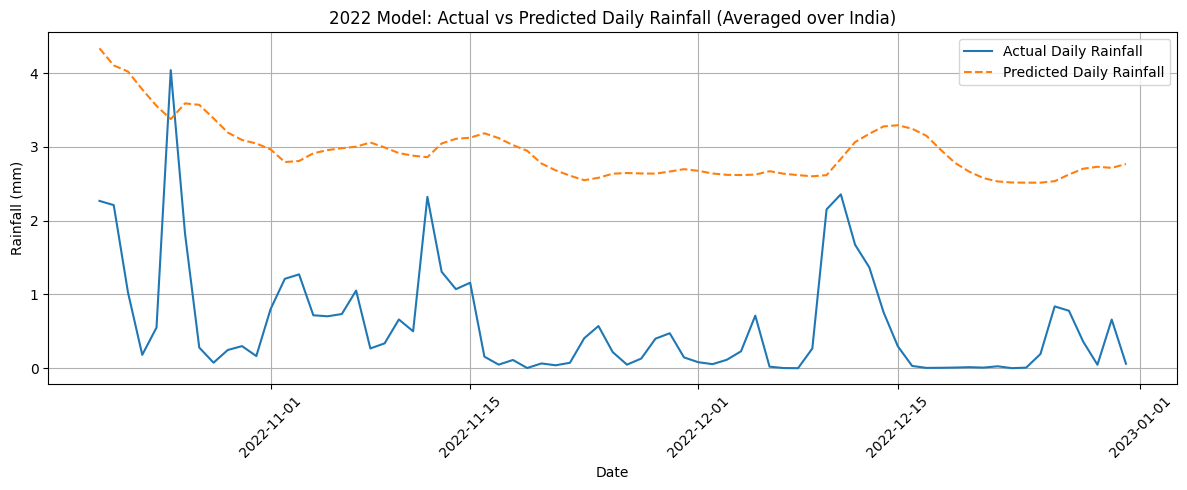

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Prepare dataset values
values = df_2022[["Rainfall"]].values
split_index = int(len(values) * 0.80)

# Scale the data
scaler = MinMaxScaler()
scaler.fit(values[:split_index])
scaled = scaler.transform(values)

# Create sequences using previous 7 days to predict the 8th day
X, y, indices = [], [], []
for i in range(7, len(scaled)):
    X.append(scaled[i-7:i])
    y.append(scaled[i])
    indices.append(i)

X = np.array(X)
y = np.array(y)
indices = np.array(indices)

# Split into training and testing sets
train_mask = indices < split_index
test_mask = indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

# Build LSTM model
model_2022 = Sequential([
    LSTM(32, activation="tanh", input_shape=(7, 1)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model_2022.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the model
history = model_2022.fit(
    X_train,
    y_train,
    epochs=80,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

# Predict and evaluate on the test set
pred_scaled = model_2022.predict(X_test, verbose=0)
actual = scaler.inverse_transform(y_test).flatten()
predicted = scaler.inverse_transform(pred_scaled).flatten()
predicted = np.maximum(predicted, 0)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
print(f"\n2022 Model Evaluation:")
print(f"MAE: {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")

# Plot actual vs predicted values
test_dates = df_2022["Date"].iloc[indices[test_mask]]
plt.figure(figsize=(12, 5))
plt.plot(test_dates, actual, label="Actual Daily Rainfall")
plt.plot(test_dates, predicted, "--", label="Predicted Daily Rainfall")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.title("2022 Model: Actual vs Predicted Daily Rainfall (Averaged over India)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Predictions for the next 7 unseen days (January 2023):
      Date  Predicted Rainfall (mm)
2023-01-01                    2.749
2023-01-02                    3.018
2023-01-03                    3.272
2023-01-04                    3.528
2023-01-05                    3.777
2023-01-06                    4.044
2023-01-07                    4.282


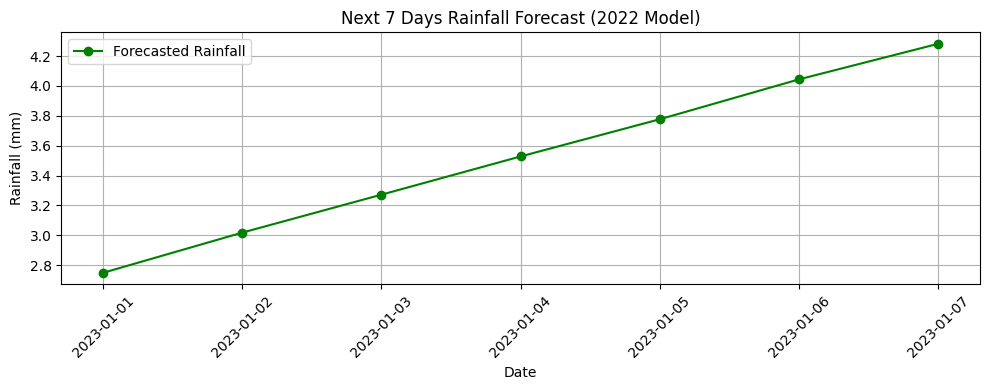

In [13]:
# Predict the next 7 unseen dates (into January 2023)
sequence = scaled[-7:].copy()
future_predictions = []

for _ in range(7):
    # Predict next step
    next_scaled = model_2022.predict(sequence.reshape(1, 7, 1), verbose=0)
    # Inverse transform to original scale
    next_value = scaler.inverse_transform(next_scaled)[0, 0]
    # Rainfall cannot be negative
    future_predictions.append(max(0, next_value))
    # Update sequence by appending prediction and removing the oldest point
    sequence = np.vstack([sequence[1:], next_scaled])

# Generate future date index
future_dates = pd.date_range(
    df_2022["Date"].iloc[-1] + pd.Timedelta(days=1),
    periods=7
)

# Create a predictions DataFrame
future_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted Rainfall (mm)": np.round(future_predictions, 3)
})

print("Predictions for the next 7 unseen days (January 2023):")
print(future_df.to_string(index=False))

# Plot the future predictions
plt.figure(figsize=(10, 4))
plt.plot(
    future_df["Date"],
    future_df["Predicted Rainfall (mm)"],
    marker="o",
    color="green",
    linestyle="-",
    label="Forecasted Rainfall"
)
plt.title("Next 7 Days Rainfall Forecast (2022 Model)")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.grid(True)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Selected district: AGAR-MALWA
Available records: 64
            Rainfall
Date                
2026-08-19       0.0
2026-08-20       0.0
2026-08-21       0.8
2026-08-22       0.0
2026-08-23       0.2
Training samples: 44
Testing samples: 13
Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 174ms/step - loss: 0.0574 - val_loss: 1.1520e-04
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.0538 - val_loss: 4.1568e-04
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.0521 - val_loss: 8.6639e-04
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0498 - val_loss: 0.0015
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0494 - val_loss: 0.0024
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 0.0487 - val_loss: 0.0032
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.0479 - val_loss: 0.0040
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0471 - val_loss: 0.0046
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0463 - val_loss: 0.0051
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.0465 - val_loss: 0.0054
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 0.0459 - val_loss: 0.0054

District: AGAR-MALWA
MAE: 2.391 mm
RMSE: 5.335 mm


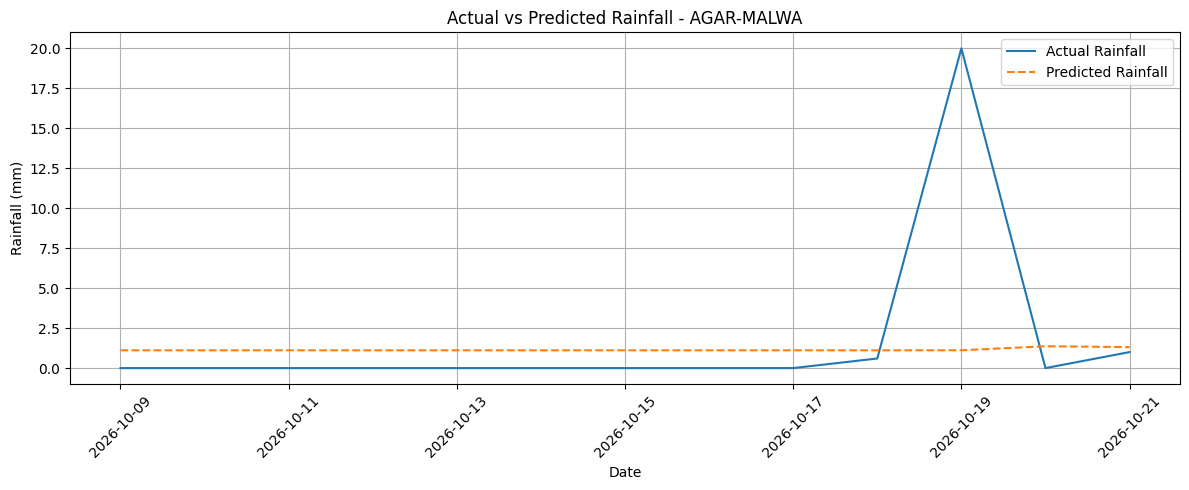


Predictions for unseen dates:
      Date  Predicted Rainfall (mm)
2026-10-22                     1.28
2026-10-23                     1.26
2026-10-24                     1.24
2026-10-25                     1.22
2026-10-26                     1.21
2026-10-27                     1.13
2026-10-28                     1.13


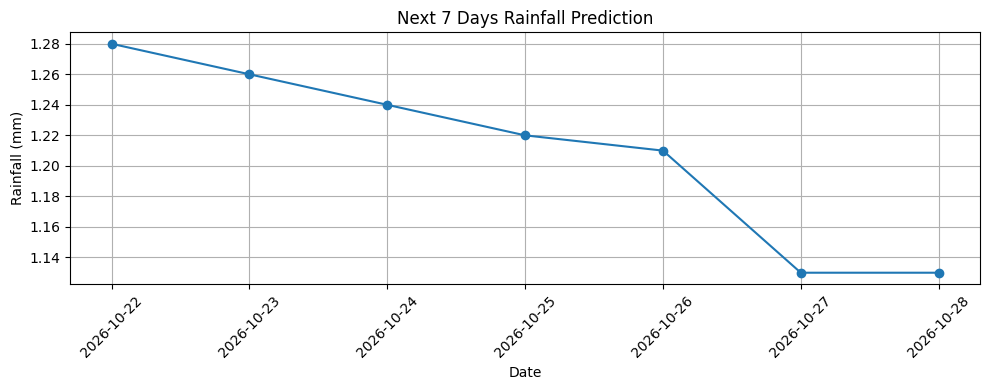

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Load dataset
df = pd.read_csv("/content/rainfall.csv")

# Clean and convert columns
df.columns = df.columns.str.strip()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Daily Actual"] = pd.to_numeric(
    df["Daily Actual"], errors="coerce"
)

# Remove invalid records
df = df.dropna(subset=["Date", "District", "Daily Actual"])

# Select one district
districts = df["District"].astype(str).str.strip()
district_name = (
    "ERODE" if districts.str.upper().eq("ERODE").any()
    else sorted(districts.unique())[0]
)

data = df[
    df["District"].astype(str).str.strip().str.upper()
    == district_name.upper()
].copy()

# Sort by date and combine duplicate dates
data = (
    data.groupby("Date")["Daily Actual"]
    .mean()
    .sort_index()
    .to_frame(name="Rainfall")
)

print("Selected district:", district_name)
print("Available records:", len(data))
print(data.head())

# Fill missing calendar dates
data = data.asfreq("D")
data["Rainfall"] = data["Rainfall"].interpolate(
    limit_direction="both"
).fillna(0)

data["Rainfall"] = data["Rainfall"].clip(lower=0)

# Normalize using training data only
values = data[["Rainfall"]].values
split_index = int(len(values) * 0.80)

if split_index <= 7 or len(values) - split_index < 1:
    raise ValueError(
        "Not enough daily records. Download more dates for this district."
    )

scaler = MinMaxScaler()
scaler.fit(values[:split_index])
scaled = scaler.transform(values)

# Create sequences using the previous 7 days
X, y, indices = [], [], []

for i in range(7, len(scaled)):
    X.append(scaled[i-7:i])
    y.append(scaled[i])
    indices.append(i)

X = np.array(X)
y = np.array(y)
indices = np.array(indices)

train_mask = indices < split_index
test_mask = indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Build LSTM model
model = Sequential([
    LSTM(32, activation="tanh", input_shape=(7, 1)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

# Predict test data
pred_scaled = model.predict(X_test, verbose=0)

actual = scaler.inverse_transform(y_test).flatten()
predicted = scaler.inverse_transform(pred_scaled).flatten()
predicted = np.maximum(predicted, 0)

# Evaluate
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"\nDistrict: {district_name}")
print(f"MAE: {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")

# Plot actual vs predicted
test_dates = data.index[indices[test_mask]]

plt.figure(figsize=(12, 5))
plt.plot(test_dates, actual, label="Actual Rainfall")
plt.plot(test_dates, predicted, "--", label="Predicted Rainfall")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.title(f"Actual vs Predicted Rainfall - {district_name}")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Predict the next 7 unseen dates
sequence = scaled[-7:].copy()
future_predictions = []

for _ in range(7):
    next_scaled = model.predict(
        sequence.reshape(1, 7, 1), verbose=0
    )

    next_value = scaler.inverse_transform(next_scaled)[0, 0]
    future_predictions.append(max(0, next_value))

    sequence = np.vstack([sequence[1:], next_scaled])

future_dates = pd.date_range(
    data.index[-1] + pd.Timedelta(days=1),
    periods=7
)

future_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted Rainfall (mm)": np.round(future_predictions, 2)
})

print("\nPredictions for unseen dates:")
print(future_df.to_string(index=False))

plt.figure(figsize=(10, 4))
plt.plot(
    future_df["Date"],
    future_df["Predicted Rainfall (mm)"],
    marker="o"
)
plt.title("Next 7 Days Rainfall Prediction")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

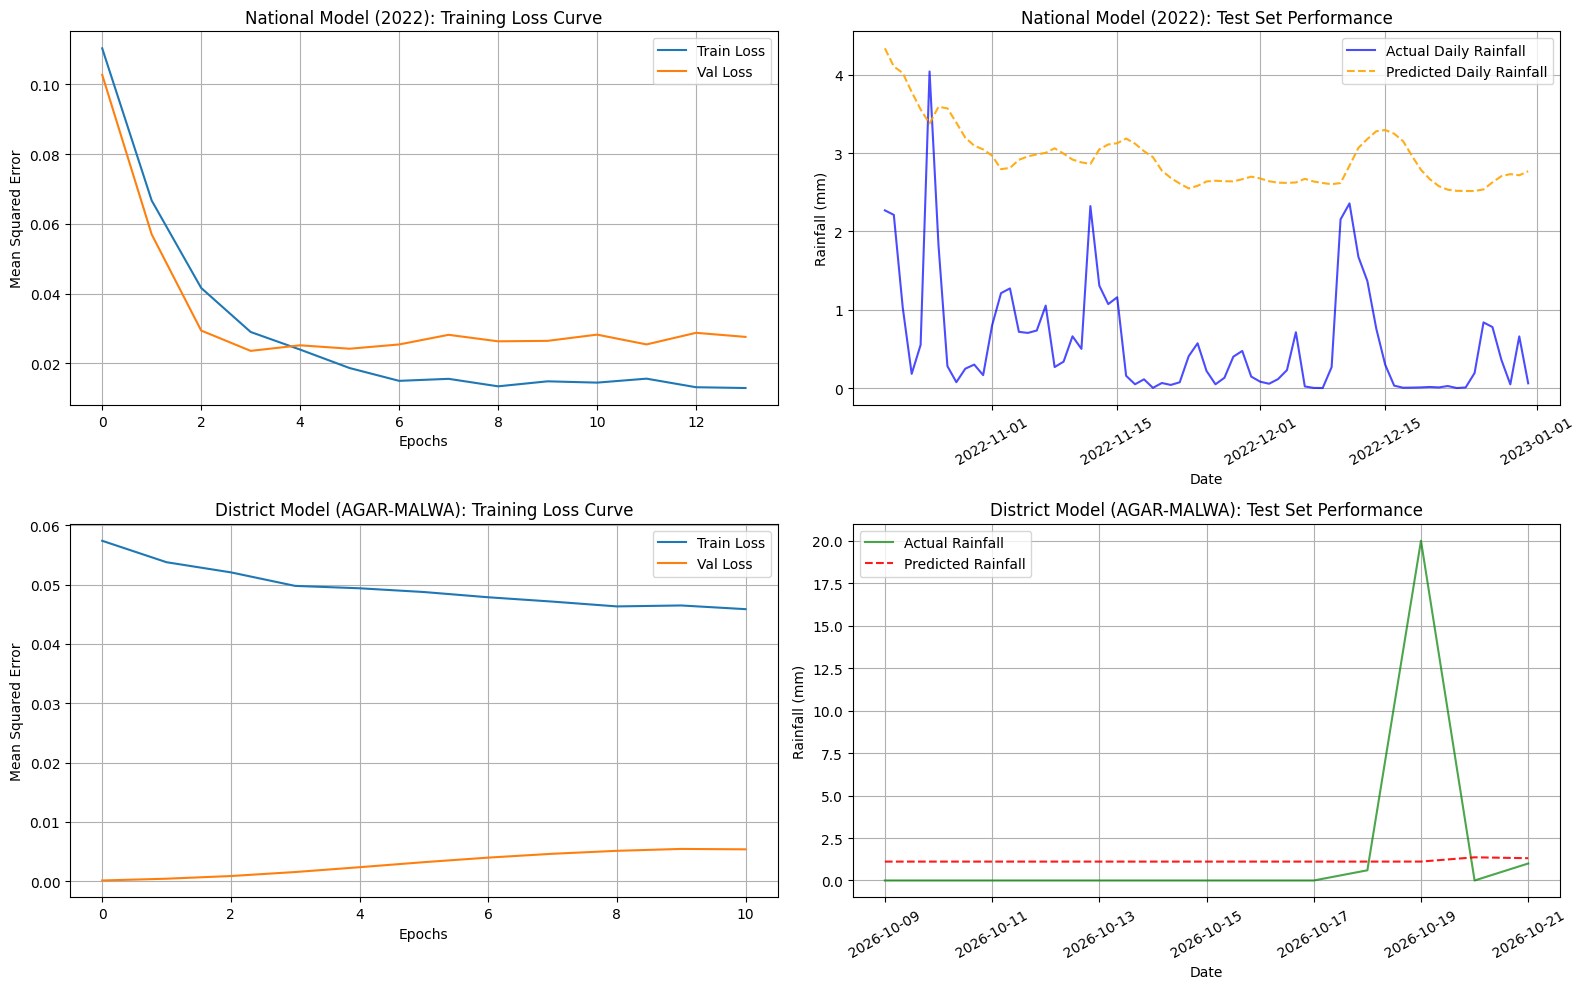

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create a unified evaluation layout
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. 2022 National Model: Loss Curve
if 'history' in globals() and hasattr(history, 'history'):
    axes[0, 0].plot(history.history['loss'], label='Train Loss')
    if 'val_loss' in history.history:
        axes[0, 0].plot(history.history['val_loss'], label='Val Loss')
    axes[0, 0].set_title('National Model (2022): Training Loss Curve')
    axes[0, 0].set_xlabel('Epochs')
    axes[0, 0].set_ylabel('Mean Squared Error')
    axes[0, 0].legend()
    axes[0, 0].grid(True)
else:
    axes[0, 0].text(0.5, 0.5, 'National training history unavailable', ha='center', va='center')

# 2. 2022 National Model: Actual vs Predicted
if 'df_2022' in globals() and 'actual' in globals() and 'predicted' in globals():
    nat_test_dates = df_2022["Date"].iloc[-len(actual):]
    axes[0, 1].plot(nat_test_dates, actual, label='Actual Daily Rainfall', color='blue', alpha=0.7)
    axes[0, 1].plot(nat_test_dates, predicted, '--', label='Predicted Daily Rainfall', color='orange', alpha=0.9)
    axes[0, 1].set_title('National Model (2022): Test Set Performance')
    axes[0, 1].set_xlabel('Date')
    axes[0, 1].set_ylabel('Rainfall (mm)')
    axes[0, 1].tick_params(axis='x', rotation=30)
    axes[0, 1].legend()
    axes[0, 1].grid(True)
else:
    axes[0, 1].text(0.5, 0.5, 'National predictions unavailable', ha='center', va='center')

# 3. District Model: Loss Curve
if 'model' in globals() and hasattr(model, 'history') and model.history.history:
    axes[1, 0].plot(model.history.history['loss'], label='Train Loss')
    if 'val_loss' in model.history.history:
        axes[1, 0].plot(model.history.history['val_loss'], label='Val Loss')
    axes[1, 0].set_title(f'District Model ({district_name}): Training Loss Curve')
    axes[1, 0].set_xlabel('Epochs')
    axes[1, 0].set_ylabel('Mean Squared Error')
    axes[1, 0].legend()
    axes[1, 0].grid(True)
else:
    axes[1, 0].text(0.5, 0.5, 'District training history unavailable', ha='center', va='center')

# 4. District Model: Actual vs Predicted
if 'model' in globals() and 'data' in globals():
    # Re-normalize specifically using the district's local dimensions to avoid variable conflicts
    dist_values = data[["Rainfall"]].values
    dist_split = int(len(dist_values) * 0.80)
    dist_scaler = MinMaxScaler()
    dist_scaler.fit(dist_values[:dist_split])
    dist_scaled = dist_scaler.transform(dist_values)

    # Re-create the localized test sets
    dist_X, dist_y = [], []
    for i in range(7, len(dist_scaled)):
        dist_X.append(dist_scaled[i-7:i])
        dist_y.append(dist_scaled[i])
    dist_X = np.array(dist_X)
    dist_y = np.array(dist_y)

    dist_test_mask = np.array(range(7, len(dist_scaled))) >= dist_split
    dist_X_test = dist_X[dist_test_mask]
    dist_y_test = dist_y[dist_test_mask]

    # Make prediction
    dist_pred_scaled = model.predict(dist_X_test, verbose=0)
    dist_actual = dist_scaler.inverse_transform(dist_y_test).flatten()
    dist_predicted = dist_scaler.inverse_transform(dist_pred_scaled).flatten()
    dist_predicted = np.maximum(dist_predicted, 0)

    dist_test_dates = data.index[-len(dist_actual):]

    axes[1, 1].plot(dist_test_dates, dist_actual, label='Actual Rainfall', color='green', alpha=0.7)
    axes[1, 1].plot(dist_test_dates, dist_predicted, '--', label='Predicted Rainfall', color='red', alpha=0.9)
    axes[1, 1].set_title(f'District Model ({district_name}): Test Set Performance')
    axes[1, 1].set_xlabel('Date')
    axes[1, 1].set_ylabel('Rainfall (mm)')
    axes[1, 1].tick_params(axis='x', rotation=30)
    axes[1, 1].legend()
    axes[1, 1].grid(True)
else:
    axes[1, 1].text(0.5, 0.5, 'District predictions unavailable', ha='center', va='center')

plt.tight_layout()
plt.show()